# Météo : comment évolue la température ?

**Problème :** Étudier la température et les précipitations dans le temps. Anomalies : température manquante, humidité hors plage.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 :Lire et explorer les données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=1))


Dimensions : (31, 5)


,date,ville,temperature_c,humidite_pct,pluie_mm
0,2026-03-01,Rabat,22.1,81,0.0
1,2026-03-02,Bouznika,22.8,50,0.0
2,2026-03-03,Rabat,25.5,44,3.5
3,2026-03-04,Rabat,24.4,51,1.2
4,2026-03-05,Bouznika,28.3,79,1.2


,date,ville,temperature_c,humidite_pct,pluie_mm
27,2026-03-28,Mohammedia,12.7,64,3.5
3,2026-03-04,Rabat,24.4,51,1.2
19,2026-03-20,Rabat,15.6,130,1.2
23,2026-03-24,Bouznika,16.1,47,3.5
22,2026-03-23,Bouznika,16.3,39,8.0


## Étape 2 :Comprendre la structure

In [2]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           31 non-null     datetime64[us]
 1   ville          31 non-null     str           
 2   temperature_c  30 non-null     float64       
 3   humidite_pct   31 non-null     int64         
 4   pluie_mm       31 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 1.3 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,31,NaN,NaN,NaN,2026-03-16 00:00:00,2026-03-01 00:00:00,2026-03-08 12:00:00,2026-03-16 00:00:00,2026-03-23 12:00:00,2026-03-31 00:00:00,NaN
ville,31,3,Rabat,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,30.0,NaN,NaN,NaN,19.956667,11.8,15.05,19.8,24.75,28.8,5.396275
humidite_pct,31.0,NaN,NaN,NaN,65.419355,39.0,50.0,65.0,77.0,130.0,19.479518
pluie_mm,31.0,NaN,NaN,NaN,2.23871,0.0,0.0,1.2,3.5,8.0,2.876419


Colonnes : ['date', 'ville', 'temperature_c', 'humidite_pct', 'pluie_mm']


## Étape 3 :Détecter les anomalies

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


date             0
ville            0
temperature_c    1
humidite_pct     0
pluie_mm         0
dtype: int64

Lignes dupliquées : 0
\nville : <StringArray>
['Rabat', 'Bouznika', 'Mohammedia']
Length: 3, dtype: str


## Étape 4 : Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["ville"] = df_clean["ville"].fillna("Inconnue").str.title()
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (31, 5)


,date,ville,temperature_c,humidite_pct,pluie_mm
0,2026-03-01,Rabat,22.1,81,0.0
1,2026-03-02,Bouznika,22.8,50,0.0
2,2026-03-03,Rabat,25.5,44,3.5
3,2026-03-04,Rabat,24.4,51,1.2
4,2026-03-05,Bouznika,28.3,79,1.2


## Étape 5 : Analyse avec Pandas et calculs NumPy

In [5]:
for col in ["temperature_c","humidite_pct","pluie_mm"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_analyse = df_clean[df_clean["humidite_pct"].between(0,100)].copy()
print("Température moyenne :", np.nanmean(df_analyse["temperature_c"]), "°C")
display(df_analyse.groupby("ville")[["temperature_c","pluie_mm"]].mean().round(2))


Température moyenne : 20.106896551724137 °C


,temperature_c,pluie_mm
ville,,
Bouznika,20.52,3.18
Mohammedia,17.37,2.31
Rabat,21.53,1.26


## Étape 6 : Visualisation avec Matplotlib

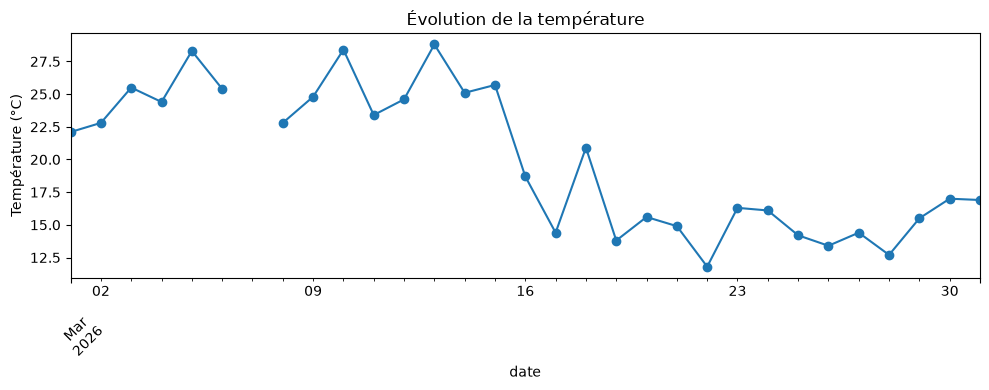

In [6]:
df_clean.groupby("date")["temperature_c"].mean().plot(kind="line", marker="o", figsize=(10,4))
plt.title("Évolution de la température")
plt.ylabel("Température (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [7]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.
